# Day 08 — Chạy model pre-label trên Google Colab (cho máy yếu)

**Dùng khi:** laptop không GPU hoặc quá chậm. Colab cho GPU miễn phí (T4) để **chạy model** (Part 2–5). **CVAT, review, đo số, viết báo cáo vẫn làm trên máy bạn.**

**Luồng:** Colab chạy `prelabel.py` → tải `colab_outputs.zip` về → nạp file nhãn vào CVAT (cách A, `docs/CVAT_AI.md`) → review → các script đo (`review_stats.py`...) chạy trên máy bạn (nhẹ, không cần GPU).

> Colab **không** nối được tới CVAT `localhost` của bạn: ta chỉ lấy file nhãn từ Colab. Bài vẫn là **cá nhân**: commit từ repo trên máy bạn.

**Trước khi chạy:** menu **Runtime → Change runtime type → T4 GPU**. Chạy các ô từ trên xuống.

## 0. Kiểm tra GPU và lấy mã nguồn

In [6]:
!nvidia-smi -L || echo "Không có GPU: vào Runtime > Change runtime type > T4 GPU"
import os
REPO_URL = "https://github.com/phdang95/K5-L23-DAY08-2A202603229-PhanHaiDang-AIPrelabel"   # có thể đổi thành repo fork của bạn (public)
if not os.path.isdir("lab"):
    !git clone -q $REPO_URL lab
%cd lab
!ls

GPU 0: Tesla T4 (UUID: GPU-f81c2a89-4d80-4878-34cf-e9220dcbb103)
/content/lab/lab
CHECKPOINTS.md				requirements-cvat.txt
cvat					requirements-local.txt
data					requirements.txt
docs					RUBRIC.md
guideline				RULES.md
GUIDE.md				scripts
K5-L23-Day08-AI-Assisted-Labeling.html	STUDENT.md
K5-L23-Day08-AI-Assisted-Labeling.md	submission
K5-L23-Day08-AI-Assisted-Labeling.pdf	SUBMISSION.md
models					tests
notebooks				walkthrough_images
README.md


## 1. Cài thư viện (torch đã có sẵn trên Colab, không cài lại)

In [7]:
!pip -q install "ultralytics>=8.4.0" opencv-python-headless pyyaml matplotlib "transformers>=5.0" huggingface_hub
!python scripts/check_env.py || true

[PASS] Python 3.13.16
[PASS] numpy 2.4.6
[PASS] PIL 11.3.0
[PASS] cv2 4.14.0
[PASS] matplotlib 3.10.0
[PASS] yaml 6.0.3
[PASS] torch 2.14.1+cu130
[PASS] ultralytics 8.4.215
[PASS] transformers 5.22.1
[PASS] GPU CUDA: Tesla T4
[PASS] git
[PASS] data/images: 36/36 ảnh
[PASS] data/split.csv
[WARN] trọng số trong models/: (chưa có)
         -> python scripts/download_models.py --set core
[WARN] HuggingFace token: chưa đăng nhập (chỉ cần cho SAM 3, tuỳ chọn)
         -> xem docs/SETUP.md mục SAM 3

SẴN SÀNG.


## 2. Tải trọng số (bài chính: 3 model, ~0.35 GB)
`core` gồm YOLO26m, YOLOE-26s, **SAM 2.1 base**. SAM là bắt buộc: muốn SAM 1 bỏ comment dòng `--set sam1`.

In [8]:
!python scripts/download_models.py --set core
# !python scripts/download_models.py --set sam1      # tuỳ chọn: SAM 1 (mobile_sam)

OK   yolo26m.pt
OK   yoloe-26s-seg.pt
OK   sam2.1_b.pt


### (Nâng cao, tuỳ chọn) SAM 3
Cần quyền tại https://huggingface.co/facebook/sam3. Lưu token vào **Colab Secrets** (chìa khoá bên trái) tên `HF_TOKEN`, bật *Notebook access*. **Không dán token vào notebook.**

In [9]:
# from google.colab import userdata
# import os
# os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
# !python scripts/download_models.py --set sam3

## 3. Part 2 — Thử 3 model trên 8 ảnh `pilot` (không phải gold)
Mỗi lần chạy ghi một dòng vào `work/runs.csv`. Xem ảnh `viz/` bằng ô kế tiếp rồi ghi `model_log.csv` **trên máy bạn**.

In [10]:
!python scripts/prelabel.py --model yolo26 --size m --split pilot --conf 0.25 --out work/prelabel/t_y26
!python scripts/prelabel.py --model yolo26 --size m --split pilot --conf 0.5  --out work/prelabel/t_y26_c05
!python scripts/prelabel.py --model yoloe --classes three_wheeler --split pilot --conf 0.25 --out work/prelabel/t_yoloe
# SAM (bắt buộc): chọn phiên bản bằng --sam (mobile_sam.pt = SAM 1, sam2.1_b.pt = SAM 2.1)
!python scripts/prelabel.py --model yolo26 --size m --classes "person,motorbike,car" --images img_004.jpg img_013.jpg --conf 0.3 --segmenter sam --sam sam2.1_b.pt --out work/prelabel/t_sam

Model: yolo26 | thiết bị: cuda | 8 ảnh | ngưỡng mặc định 0.25
  img_032.jpg: 23 box
Đã ghi 215 box (0 có mask) cho 8 ảnh -> work/prelabel/t_y26/pre.coco.json
Tên thô KHÔNG có trong ánh xạ (bị bỏ im lặng nếu bạn không đọc dòng này!): umbrella×10, handbag×2, traffic light×2, backpack×2
Số box theo lớp: person=131, motorbike=55, car=17, bicycle=8, truck=3, bus=1
Thời gian: nạp 0.4s, chạy 9.8s (1.23s/ảnh)
Ảnh xem nhanh: work/prelabel/t_y26/viz/
Model: yolo26 | thiết bị: cuda | 8 ảnh | ngưỡng mặc định 0.5
  img_032.jpg: 17 box
Đã ghi 139 box (0 có mask) cho 8 ảnh -> work/prelabel/t_y26_c05/pre.coco.json
Tên thô KHÔNG có trong ánh xạ (bị bỏ im lặng nếu bạn không đọc dòng này!): umbrella×5, handbag×2, traffic light×1, backpack×1
Số box theo lớp: person=87, motorbike=32, car=14, bicycle=3, truck=2, bus=1
Thời gian: nạp 0.2s, chạy 2.7s (0.34s/ảnh)
Ảnh xem nhanh: work/prelabel/t_y26_c05/viz/
Prompts (3): 'tuk-tuk'→three_wheeler, 'cyclo'→three_wheeler, 'cargo tricycle'→three_wheeler
Model: yoloe 

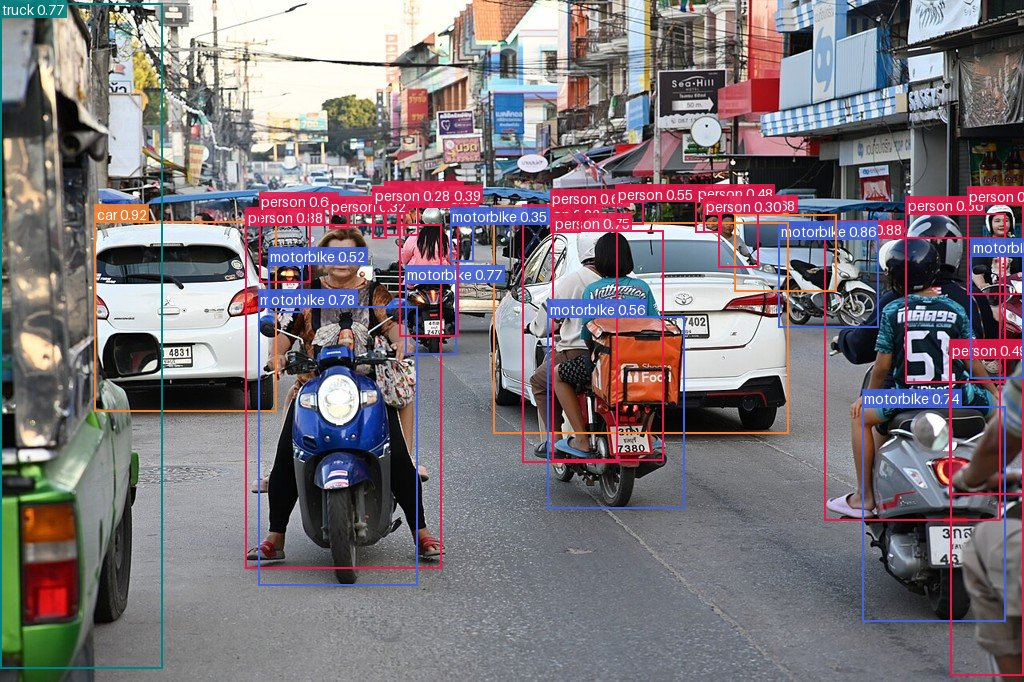

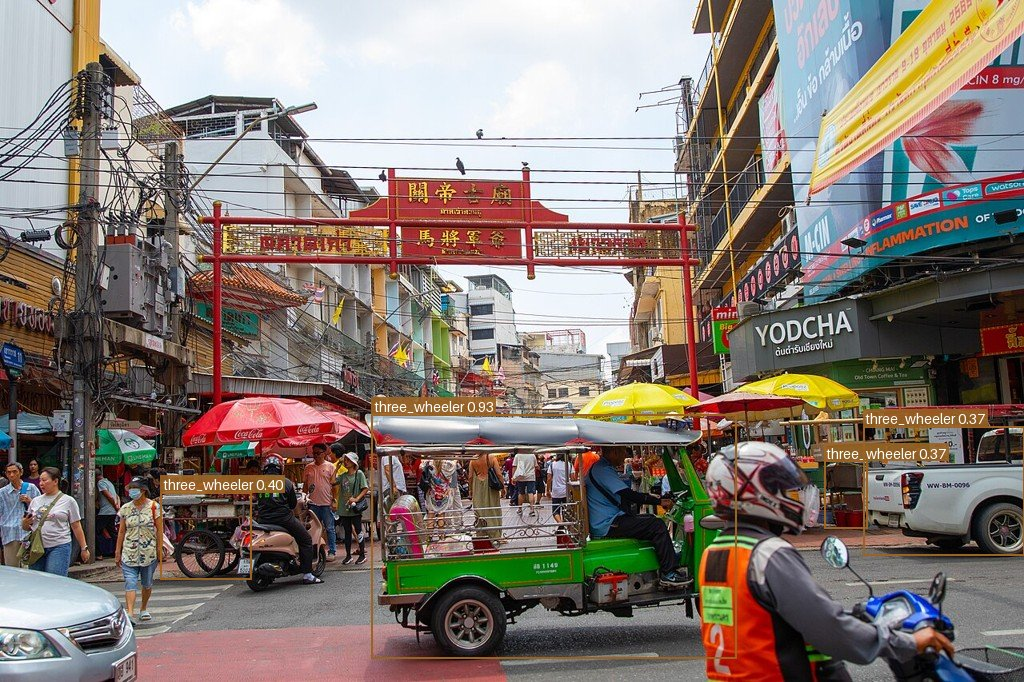

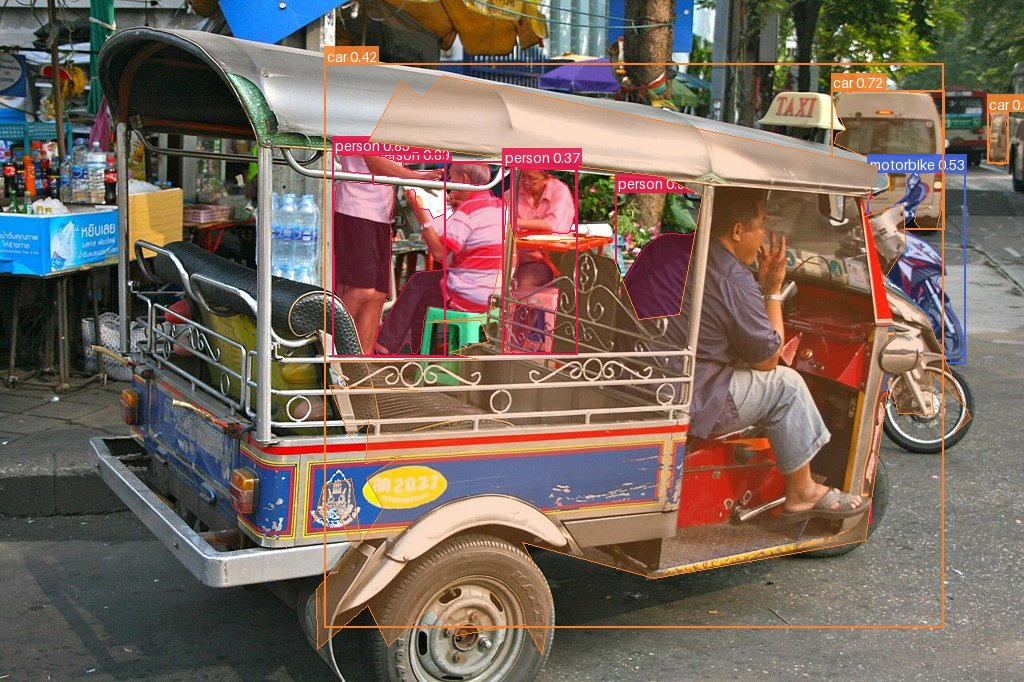

In [11]:
from IPython.display import Image, display
display(Image("work/prelabel/t_y26/viz/img_011.jpg"))
display(Image("work/prelabel/t_yoloe/viz/img_002.jpg"))
display(Image("work/prelabel/t_sam/viz/img_013.jpg"))

## 4. Chạy mọi ảnh ở ngưỡng thấp (nguồn cho Part 3, 4)
Chạy **sau khi** bạn đã gán xong 4 ảnh gold bằng tay (Part 1). Ảnh gold không bao giờ được xem pre-label trước khi gán xong.

In [12]:
!python scripts/prelabel.py --model yolo26 --size m --split all --conf 0.05 --out work/prelabel/y26_all --no-viz
!python scripts/prelabel.py --model yoloe --classes three_wheeler --split all --conf 0.05 --out work/prelabel/yoloe_all --no-viz

Model: yolo26 | thiết bị: cuda | 36 ảnh | ngưỡng mặc định 0.05
  img_036.jpg: 61 box
Đã ghi 1669 box (0 có mask) cho 36 ảnh -> work/prelabel/y26_all/pre.coco.json
Tên thô KHÔNG có trong ánh xạ (bị bỏ im lặng nếu bạn không đọc dòng này!): banana×104, umbrella×57, chair×29, handbag×28, bottle×26, potted plant×22, apple×18, backpack×16, orange×16, traffic light×10, dining table×10, cup×6, bowl×4, bench×2, dog×2, stop sign×2, cell phone×2, book×1
Số box theo lớp: person=877, motorbike=495, car=195, bicycle=58, truck=35, bus=9
Thời gian: nạp 0.2s, chạy 4.2s (0.12s/ảnh)
Prompts (3): 'tuk-tuk'→three_wheeler, 'cyclo'→three_wheeler, 'cargo tricycle'→three_wheeler
Model: yoloe | thiết bị: cuda | 36 ảnh | ngưỡng mặc định 0.05
/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(
  img_036.jpg: 0 box
Đã ghi 125 box (0 có mask) cho 36 ảnh -> work/prelabel/yoloe_all/pre.coco.json
Số bo

## 5. Part 3 — tải kết quả thô về máy, quét ngưỡng ở máy bạn
Chạy ô dưới, tải `colab_stage1.zip`, giải nén vào repo trên máy, rồi chạy `threshold_sweep.py` (xem `docs/THRESHOLD.md`).

In [13]:
!zip -rq colab_stage1.zip work/prelabel/y26_all work/prelabel/yoloe_all work/runs.csv
from google.colab import files
files.download("colab_stage1.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. Part 4 — gộp batch với ngưỡng của bạn
Sau Part 3 (`threshold_sweep.py` chạy **trên máy bạn**), dán chuỗi ngưỡng vào `THR`. Cài **ảnh bẫy** (`inject_traps.py`) nên làm trên máy bạn để hạt giống và đáp án nằm trong repo của bạn.

In [14]:
THR = "person=0.35,bicycle=0.3,motorbike=0.35,car=0.3,bus=0.3,truck=0.4,three_wheeler=0.35"   # <-- thay bằng ngưỡng của BẠN
!python scripts/merge_prelabels.py work/prelabel/yoloe_all/pre.coco.json work/prelabel/y26_all/pre.coco.json --thr "$THR" --conf 0.3 --iou 0.6 --split batch,gold --out work/prelabel/merged_review/pre.coco.json
# MSSV = "22001234"   # thay bằng MSHV của bạn rồi bỏ comment dòng dưới nếu muốn cài bẫy ở Colab
# !python scripts/inject_traps.py --pre work/prelabel/merged_review/pre.coco.json --student $MSSV

Gộp 2 file -> 553 box (person=288, motorbike=143, car=69, three_wheeler=30, bicycle=14, truck=5, bus=4) -> work/prelabel/merged_review/pre.coco.json
Box bị loại (dưới ngưỡng, hoặc chồng lên box ưu tiên cao hơn): y26_all:person(dưới ngưỡng)×369, y26_all:motorbike(dưới ngưỡng)×239, y26_all:car(dưới ngưỡng)×83, yoloe_all:three_wheeler(dưới ngưỡng)×71, y26_all:bicycle(dưới ngưỡng)×21, y26_all:truck(dưới ngưỡng)×21, y26_all:car×7, y26_all:truck×3, y26_all:bus×2, y26_all:bus(dưới ngưỡng)×2


## 7. Part 5 — mask SAM cho 3 vật (bằng click)
Sửa toạ độ click theo vật bạn chọn; xem `docs/MODELS.md` mục B1.

Mask: 317255 px (45.4% ảnh), 1 polygon -> submission/masks/tuktuk_img013.jpg
Mask: 14844 px (2.1% ảnh), 5 polygon -> submission/masks/cyclo_img010.jpg
Mask: 88408 px (12.7% ảnh), 1 polygon -> submission/masks/occluded_img017.jpg
=== tuktuk_img013.jpg ===


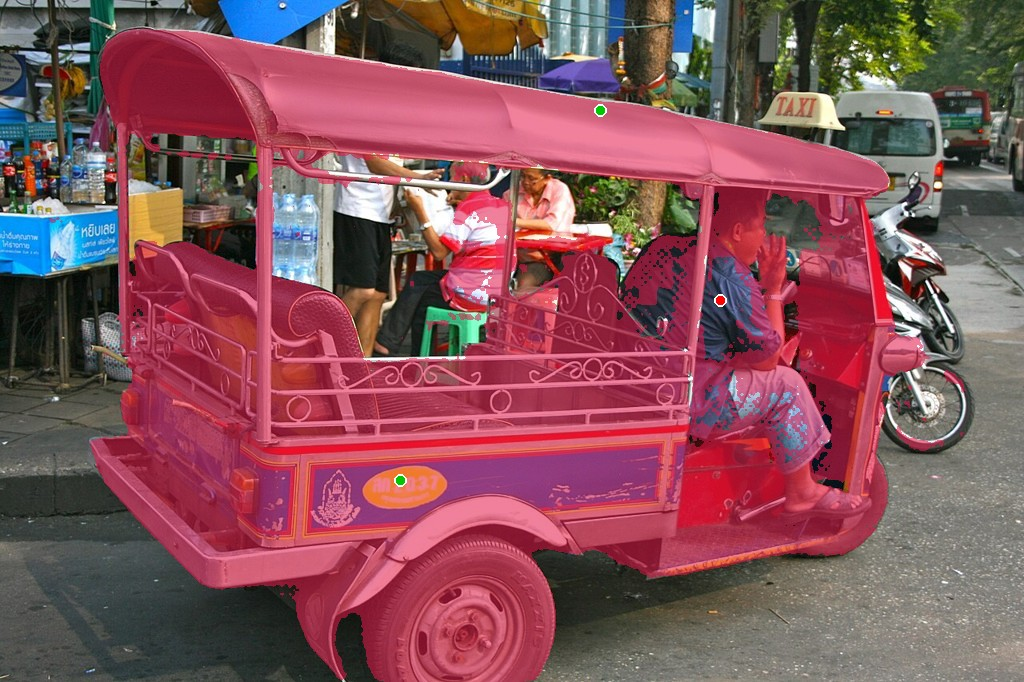

=== cyclo_img010.jpg ===


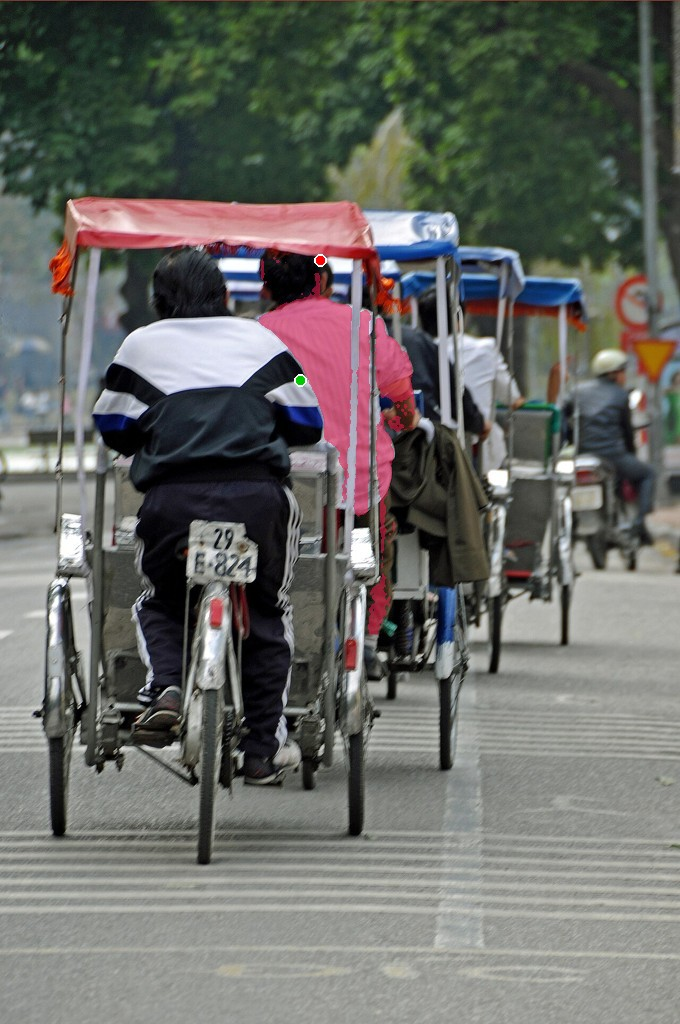

=== occluded_img017.jpg ===


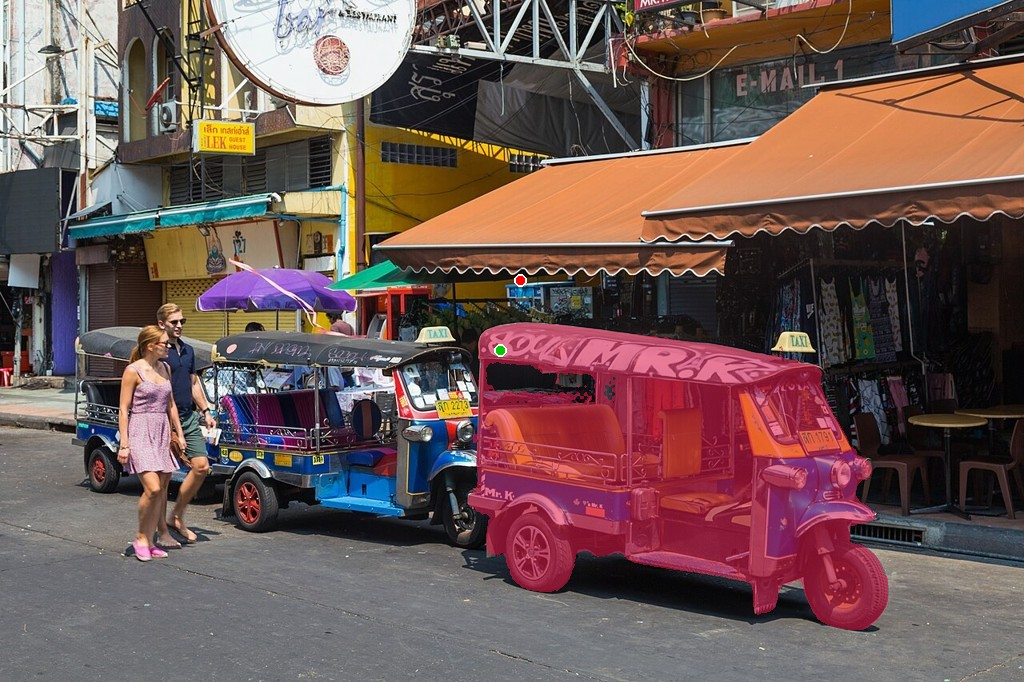

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
SAM = "sam2.1_b.pt"

# 1. Tuk-tuk có người lái (img_013)
!python scripts/sam2_points.py --image img_013.jpg --pos "400,480" --pos "600,110" --neg "720,300" --sam $SAM --out submission/masks --name tuktuk_img013

# 2. Xích lô (img_010)
!python scripts/sam2_points.py --image img_010.jpg --pos "300,380" --neg "320,260" --sam $SAM --out submission/masks --name cyclo_img010

# 3. Vật bị che (img_017)
!python scripts/sam2_points.py --image img_017.jpg --pos "500,350" --neg "520,280" --sam $SAM --out submission/masks --name occluded_img017

# Hiển thị cả 3 ảnh để kiểm tra
from IPython.display import Image, display
for name in ["tuktuk_img013.jpg", "cyclo_img010.jpg", "occluded_img017.jpg"]:
    print("=== " + name + " ===")
    display(Image(f"submission/masks/{name}"))

# Nén và tải về máy
!zip -rq masks.zip submission/masks
from google.colab import files
files.download("masks.zip")

## 8. Tải kết quả về máy
Gói `work/prelabel` (file nhãn), `work/runs.csv` (nhật ký lần chạy, để copy sang `model_log.csv`) và `submission/masks`. Giải nén vào **repo trên máy bạn**, giữ nguyên đường dẫn.

In [16]:
!zip -rq colab_outputs.zip work/prelabel work/runs.csv submission/masks 2>/dev/null || true
from google.colab import files
files.download("colab_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Tiếp theo (trên máy bạn):** giải nén `colab_outputs.zip` vào thư mục repo → làm theo `GUIDE.md` từ bước nạp vào CVAT. Nhớ: ghi `model_log.csv` bằng nhận xét **của bạn** khi nhìn ảnh `viz/`; số trong `runs.csv` do Colab chạy (ghi chú `device = cuda`, thời gian khác máy bạn).